# Chapitre 10 - Cours 5 : les sorties des workflows, Hadoop et les bases distribuées

À quoi sert un job de lots, et que fait-on de ce qu'il produit ? Ce n'est presque jamais
un rapport destiné à un humain : c'est une structure de données (un index, une table de
recommandations, un modèle) qu'un système en ligne va servir. Ce cours montre comment
produire ces sorties sans compromettre ni la base de production ni la capacité à
corriger une erreur. Il couvre les sections *The Output of Batch Workflows* (*Building search indexes*, *Key-value stores as batch process output*, *Philosophy of batch process outputs*) et *Comparing Hadoop to Distributed Databases*.

**Plan.**

1. La philosophie des sorties : entrées immuables, sorties jetables.
2. Construire un index de recherche par lots.
3. Construire une base clé-valeur par lots plutôt qu'écrire dans la base de production.
4. Hadoop face aux bases de données distribuées (MPP).




In [1]:
import math
import os
import shutil
import sqlite3
import tempfile
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_sorties_")

## 1. La philosophie des sorties (section *Philosophy of batch process outputs*)

Un job de lots traite son entrée comme **immuable** et produit sa sortie **de zéro**,
sans effet de bord sur des systèmes externes. Le livre en tire plusieurs bénéfices :

- **tolérance aux fautes humaines** : si un déploiement introduit un bogue, on revient à
  l'ancien code et on relance, ou on rebascule sur la sortie précédente, conservée dans
  un autre répertoire ; une base modifiée en place par du code bogué, elle, reste
  corrompue après le retour à l'ancien code ;
- **irréversibilité minimale** : comme une erreur se répare facilement, on peut
  développer plus vite ;
- **relances automatiques** : une tâche en échec est simplement relancée, puisque la
  même entrée donne la même sortie ; les sorties partielles sont jetées ;
- **réutilisation** : les mêmes fichiers d'entrée servent à plusieurs jobs, dont des jobs
  de contrôle qui comparent la sortie à celle de la veille.

Démonstration : un job quotidien calcule le panier moyen par pays. La version 2 du code
contient un bogue (elle compte les montants en centimes). On compare deux architectures :
sorties versionnées publiées par un pointeur atomique, et mise à jour en place d'une
table.

In [2]:
rng = np.random.default_rng(1)
ventes = pd.DataFrame({"pays": rng.choice(["FR", "DE", "US", "JP"], 20_000), "montant": rng.gamma(2, 30, 20_000).round(2)})


def job_v1(df):
    return df.groupby("pays").montant.mean().round(2)


def job_v2_bogue(df):
    return (df.groupby("pays").montant.mean() * 100).round(2)      # bogue : centimes


base = os.path.join(WORK, "panier_moyen")
os.makedirs(base)
journal = []
for version, job in [("v1", job_v1), ("v2", job_v2_bogue)]:
    d_ = os.path.join(base, version)
    os.makedirs(d_)
    job(ventes).to_csv(os.path.join(d_, "part-00000.csv"))
    B.publish_version(base, d_)
    journal.append({"étape": f"déploiement {version}", "version publiée": B.current_version(base),
                    "FR lu par le service": pd.read_csv(os.path.join(base, "current", "part-00000.csv"), index_col=0).loc["FR"].iloc[0]})
B.publish_version(base, os.path.join(base, "v1"))                 # retour arrière : un seul renommage
journal.append({"étape": "retour arrière", "version publiée": B.current_version(base),
                "FR lu par le service": pd.read_csv(os.path.join(base, "current", "part-00000.csv"), index_col=0).loc["FR"].iloc[0]})
# architecture « en place » : la v2 écrase les valeurs de la table de production
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE panier (pays TEXT PRIMARY KEY, moyen REAL)")
for job, lib in [(job_v1, "déploiement v1"), (job_v2_bogue, "déploiement v2"), (job_v1, "retour arrière du code")]:
    if lib != "retour arrière du code":
        con.executemany("INSERT OR REPLACE INTO panier VALUES (?, ?)", list(job(ventes).items()))
    journal.append({"étape": f"[en place] {lib}", "version publiée": "-",
                    "FR lu par le service": con.execute("SELECT moyen FROM panier WHERE pays='FR'").fetchone()[0]})
pd.DataFrame(journal).set_index("étape")

,version publiée,FR lu par le service
étape,,
déploiement v1,v1,60.15
déploiement v2,v2,6014.98
retour arrière,v1,60.15
[en place] déploiement v1,-,60.15
[en place] déploiement v2,-,6014.98
[en place] retour arrière du code,-,6014.98


Avec des sorties versionnées, le retour arrière est un simple changement de pointeur
(`os.replace` d'un lien symbolique, atomique) : le service retrouve instantanément la
bonne valeur. Dans l'architecture en place, revenir à l'ancien **code** ne répare pas
les **données** : il faut relancer un calcul de réparation, et si la sortie avait été
mélangée à d'autres écritures, on ne saurait même plus quoi réparer. (Dans le cas d'un
job incrémental qui modifie la table au lieu de la recalculer, ce serait pire encore.)

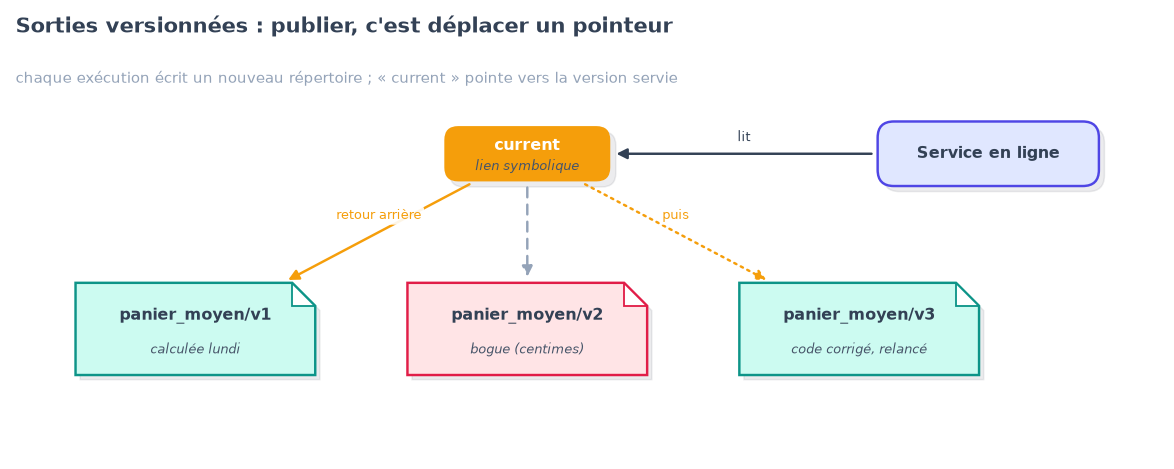

In [3]:
d = Diagram(12.5, 3.9, title="Sorties versionnées : publier, c'est déplacer un pointeur",
            subtitle="chaque exécution écrit un nouveau répertoire ; « current » pointe vers la version servie")
d.box("v1", 2.0, 1.4, "panier_moyen/v1", sub="calculée lundi", color=TEAL, kind="doc", w=2.6, h=1.0)
d.box("v2", 5.6, 1.4, "panier_moyen/v2", sub="bogue (centimes)", color=ROSE, kind="doc", w=2.6, h=1.0)
d.box("v3", 9.2, 1.4, "panier_moyen/v3", sub="code corrigé, relancé", color=TEAL, kind="doc", w=2.6, h=1.0)
d.box("cur", 5.6, 3.3, "current", sub="lien symbolique", color=AMBER, kind="tag", w=1.8, h=0.6)
d.box("svc", 10.6, 3.3, "Service en ligne", color=INDIGO, w=2.4, h=0.7)
d.arrow("cur", "v1", "retour arrière", color=AMBER)
d.arrow("cur", "v2", "", color=GRAY, style="dashed")
d.arrow("cur", "v3", "puis", color=AMBER, style="dotted")
d.arrow("svc", "cur", "lit")
d.show()

> **À retenir.** Entrées immuables et sorties regénérées de zéro rendent un job
> rejouable : une erreur se répare en relançant ou en rebasculant sur une version
> précédente. C'est la tolérance aux fautes **humaines**, que les bases modifiées en
> place n'offrent pas.

## 2. Construire un index de recherche par lots (section *Building search indexes*)

La première utilisation de MapReduce chez Google fut de construire l'index de son moteur
de recherche (le livre rappelle que Hadoop MapReduce reste un bon moyen de construire des index pour Lucene/Solr). Un **index inversé** associe à chaque terme la liste des documents qui le
contiennent (sa *liste de postings*, chapitre 3). En MapReduce : le mappeur
émet (terme, identifiant de document) pour chaque mot ; le shuffle regroupe par terme ;
le réducteur écrit la liste triée. Plus réaliste : on **partitionne par document**, et
chaque réducteur construit l'index complet d'une partition de documents, comme le font
les moteurs distribués (une requête interroge alors toutes les partitions).

In [4]:
docs = B.make_documents(4000, vocab=3000, words_per_doc=60, seed=2)
doc_shards = [[(d_, t) for d_, t in docs.items() if d_ % 4 == i] for i in range(4)]


def mappeur_index(rec):
    doc_id, texte = rec
    for pos, mot in enumerate(texte.split()):
        yield mot, [doc_id, pos]


def reducteur_postings(mot, occurrences):
    par_doc = defaultdict(list)
    for doc_id, pos in occurrences:
        par_doc[doc_id].append(pos)
    yield [mot, sorted(par_doc.items())]


t0 = time.perf_counter()
index_parts, st_idx = B.run_mapreduce(doc_shards, mappeur_index, reducteur_postings, n_reducers=4)
duree_index = time.perf_counter() - t0
index = {mot: dict(post) for part in index_parts for mot, post in part}
print(f"{len(docs)} documents, {st_idx.map_output_records:,} occurrences, {len(index):,} termes, "
      f"construit en {duree_index:.1f} s".replace(",", " "))


def recherche(*mots):
    """Documents contenant tous les mots (intersection des listes de postings)."""
    ens = [set(index.get(m, {})) for m in mots]
    return sorted(set.intersection(*ens)) if ens else []


mots_freq = sorted(index, key=lambda m: -len(index[m]))
q = (mots_freq[3], mots_freq[40])
res = recherche(*q)
verif = [d_ for d_, t in docs.items() if q[0] in t.split() and q[1] in t.split()]
assert res == sorted(verif)
print(f"requête {q} : {len(res)} documents, identiques à un parcours complet")

4000 documents  240 000 occurrences  3 000 termes  construit en 1.1 s
requête ('pete', 'kate') : 513 documents, identiques à un parcours complet


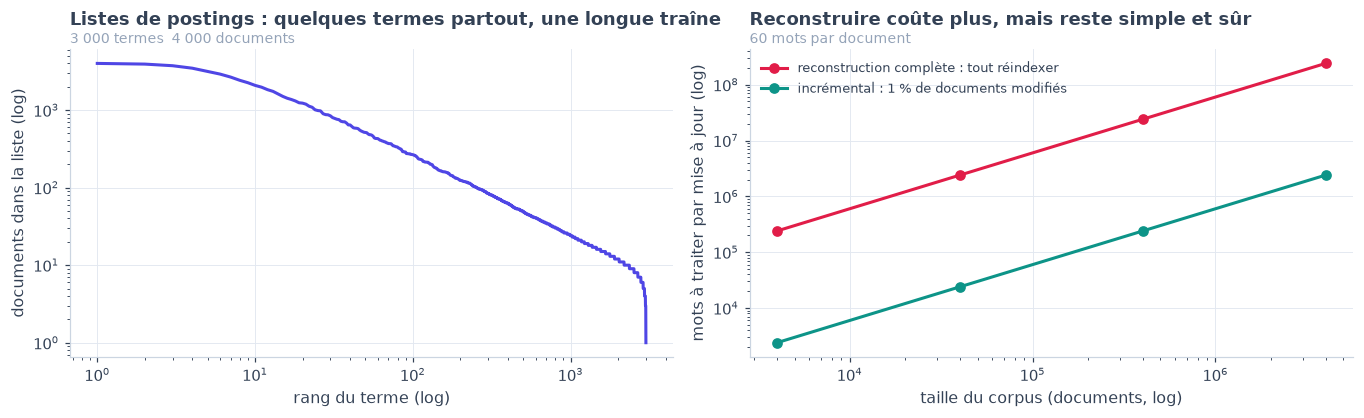

In [5]:
tailles = np.array(sorted((len(v) for v in index.values()), reverse=True))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
axes[0].loglog(np.arange(1, len(tailles) + 1), tailles, color=INDIGO)
axes[0].set_xlabel("rang du terme (log)"); axes[0].set_ylabel("documents dans la liste (log)")
axes[0].set_title("Listes de postings : quelques termes partout, une longue traîne")
subtitle(axes[0], f"{len(index):,} termes, {len(docs):,} documents".replace(",", " "))
# reconstruire tout l'index chaque nuit, ou mettre à jour ?
n_total = np.array([4000, 40_000, 400_000, 4_000_000])
modif = 0.01
axes[1].loglog(n_total, n_total * 60, "o-", color=ROSE, label="reconstruction complète : tout réindexer")
axes[1].loglog(n_total, n_total * 60 * modif, "o-", color=TEAL, label="incrémental : 1 % de documents modifiés")
axes[1].set_xlabel("taille du corpus (documents, log)"); axes[1].set_ylabel("mots à traiter par mise à jour (log)")
axes[1].set_title("Reconstruire coûte plus, mais reste simple et sûr")
subtitle(axes[1], "60 mots par document")
axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Les fichiers d'index produits sont immuables : une fois écrits, on les copie vers les
serveurs de recherche et on bascule. Si les documents changent, on peut relancer tout le
job périodiquement et remplacer l'index entier : coûteux quand peu de documents
changent, mais simple à raisonner (entrée, sortie, rien d'autre). L'alternative est
d'indexer seulement les changements et de fusionner les segments en arrière-plan, comme
Lucene (et comme les arbres LSM du chapitre 3).

> **À retenir.** Un index inversé se construit naturellement par lots : le shuffle sur le
> terme (ou un partitionnement par document) fait tout le travail de regroupement.
> L'index produit est un fichier immuable qu'on publie d'un bloc.